# Lezione 07 — Inflazione e tassi stocastici: pricing Monte Carlo di un inflation-linked bond

## 1. Sintesi del Caso, Domanda Quantitativa e Informazione Disponibile

### Contesto del Caso
Il lavoro riguarda la valutazione finanziaria di un'obbligazione indicizzata all'inflazione (inflation-linked bond) con cedole semestrali indicizzate e protezione del capitale nominale a scadenza mediante un floor. La valutazione dipende congiuntamente da due fattori di rischio stocastici e correlati:
- il **tasso istantaneo di inflazione** $i_t$, descritto da un processo di Ornstein--Uhlenbeck (OU);
- il **tasso nominale istantaneo privo di rischio** $r_t$, descritto da un processo di Cox--Ingersoll--Ross (CIR).

### Domanda Quantitativa
> **Qual è il valore corrente dell'inflation-linked bond ottenuto mediante simulazione Monte Carlo, e quale ruolo assumono l'indicizzazione, il rimborso protetto e la dipendenza tra inflazione e tasso nominale?**

### Variabile Finale e Informazione Disponibile
- **Variabile finale di interesse:** Il prezzo Monte Carlo stimato $\widehat V_M$, ottenuto come media sui percorsi simulati dei valori attuali dei flussi di cassa del titolo (cedole stocastiche e rimborso del capitale a scadenza), unitamente alla sua misura di precisione numerica (errore standard e intervallo di confidenza al 95%).
- **Informazione disponibile:** 
  - Dinamiche continue dei due fattori di rischio:
    $$di_t = \kappa_i(\theta_i - i_t)\,dt + \sigma_i\,dW_t^{(i)}$$
    $$dr_t = \kappa_r(\theta_r - r_t)\,dt + \sigma_r\sqrt{r_t}\,dW_t^{(r)}$$
    con shock correlati $dW_t^{(i)}dW_t^{(r)} = \rho\,dt$.
  - Struttura del contratto: valore facciale $N=100$, scadenza $T=5$ anni, tasso cedolare annuo $c=1,5\%$ con cedole semestrali non protette dalla deflazione $C_{t_j} = \frac{c}{2} N J_{t_j}$, rimborso del capitale protetto da floor $R_T = N \max(J_T, 1)$, dove $J_t = \exp\left(\int_0^t i_s\,ds\right)$ è il fattore di indicizzazione.
  - Parametri di simulazione e di mercato definiti a fini didattici: $i_0=0,025$, $\kappa_i=0,80$, $\theta_i=0,020$, $\sigma_i=0,015$, $r_0=0,030$, $\kappa_r=1,20$, $\theta_r=0,030$, $\sigma_r=0,10$, $\rho=0,25$, $\Delta t = 1/12$, $M=50.000$, seed $= 12345$.

---

## 2. Quantità da Stimare o Calcolare

1. **Prezzo Monte Carlo del bond** ($\widehat V_M$).
2. **Errore standard Monte Carlo** del prezzo $SE(\widehat V_M)$ e relativo **intervallo di confidenza al 95%**.
3. **Valore attuale medio delle cedole** ($\widehat{PV}_C$).
4. **Valore attuale medio del rimborso del capitale** ($\widehat{PV}_R$).
5. **Probabilità simulata di deflazione cumulata a scadenza**, $\widehat{\mathbb P}(J_T < 1)$.
6. **Media e deviazione standard simulate** delle variabili terminali $i_T$, $r_T$ e $J_T$.

---

## 3. Output Richiesti

### Tabelle

1. **Tabella 1:** Tabella dei parametri del caso.
2. **Tabella 2:** Tabella di sintesi del pricing (valore attuale medio delle cedole, valore attuale medio del rimborso, prezzo Monte Carlo del bond).
3. **Tabella 3:** Tabella di diagnostica Monte Carlo per $M = 1.000, 5.000, 10.000, 50.000$ (prezzo stimato ed errore standard stimato).
4. **Tabella 4:** Tabella delle statistiche terminali di $i_T$, $r_T$ e $J_T$.

### Grafici

1. **Figura 1:** Traiettorie simulate del tasso di inflazione $i_t$.
2. **Figura 2:** Traiettorie simulate del tasso nominale $r_t$.
3. **Figura 3:** Distribuzione simulata del fattore di indicizzazione terminale $J_T$.
4. **Figura 4:** Distribuzione simulata dei valori attuali $V^{(k)}$.
5. **Figura 5:** Grafico di convergenza della stima Monte Carlo al crescere di $M$.

---

## 4. Controlli Richiesti

1. **Controllo 1 (Correlazione empirica):** Verifica che la correlazione empirica degli shock simulati sia coerente con $\rho = 0,25$.
2. **Controllo 2 (Positività del fattore di indicizzazione):** Verifica che $J_{t_j}^{(k)} > 0$ per ogni replica $k$ e per ogni data $t_j$.
3. **Controllo 3 (Rispetto del floor sul capitale):** Verifica che il rimborso soddisfi $R_T^{(k)} \geq N$ per ogni replica $k$.
4. **Controllo 4 (Rilevazione tassi negativi nel CIR):** Conteggio e documentazione di eventuali valori negativi di $r_t$ prodotti dalla discretizzazione numerica, senza imporre automaticamente $r_t = 0$.
5. **Controllo 5 (Decomposizione del prezzo):** Verifica che la somma del valore attuale medio delle cedole e del valore attuale medio del rimborso uguagli il prezzo Monte Carlo ($\widehat V_M = \widehat{PV}_C + \widehat{PV}_R$).
6. **Controllo 6 (Tasso di convergenza Monte Carlo):** Verifica che l'errore standard diminuisca al crescere di $M$ in modo compatibile con l'ordine $\mathcal{O}(1/\sqrt{M})$.
7. **Controllo 7 (Sensibilità alla griglia temporale):** Verifica della stabilità del prezzo rispetto a un raffinamento della griglia temporale ($\Delta t$).

---

## 5. Vincolo della Scheda Caso

Si esplicita che la Scheda Caso costituisce la **specifica vincolante del lavoro**. Tutte le variabili, le formule, le relazioni funzionali, i parametri, gli output e i controlli stabiliti non devono essere modificati durante lo svolgimento dell'analisi.

# Flusso Logico-Teorico Risolutivo del Caso

| Passo | Finalità risolutiva | Formula, definizione, proprietà o teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| **1** | **Inquadramento del contratto e dello stato informativo** | Struttura dei flussi di un *Inflation-Linked Bond* con *floor* sul capitale nominale.<br><br>Griglia temporale discretizzata $t_0, t_1, \dots, t_N$ con passo $\Delta t = 1/12$. | Identificazione del valore facciale $N=100$, scadenza $T=5$, frequenza cedolare semestrale ($t_j \in \{6, 12, \dots, 60\}$) e scadenze dei flussi $C_{t_j}$ e $R_T$. | **Tabella 1:** Tabella dei parametri del caso.<br>**Controllo 5:** Struttura decomponibile del titolo. |
| **2** | **Formulazione dei processi stocastici continui e della dipendenza** | **Processo OU** (Inflazione):<br>$$di_t = \kappa_i(\theta_i - i_t)dt + \sigma_i dW_t^{(i)}$$<br>**Processo CIR** (Tasso nominale):<br>$$dr_t = \kappa_r(\theta_r - r_t)dt + \sigma_r\sqrt{r_t}dW_t^{(r)}$$<br>con $dW_t^{(i)}dW_t^{(r)} = \rho dt$.<br>Condizione di Feller: $2\kappa_r\theta_r \geq \sigma_r^2$. | Modellizzazione congiunta di inflazione (con valori ammissibili $i_t < 0$) e tasso privo di rischio privo di deriva negativa al continuo, con correlazione stocastica $\rho = 0,25$. | **Figura 1:** Traiettorie $i_t$.<br>**Figura 2:** Traiettorie $r_t$.<br>**Controllo 4:** Rilevazione e documentazione dei tassi $r_t < 0$ prodotti dalla discretizzazione. |
| **3** | **Generazione degli shock normali correlati** | **Decomposizione di Cholesky** su matrice di covarianza/correlazione o combinazione lineare:<br>$$Z_t^{(i)} = Z_{1,t}$$<br>$$Z_t^{(r)} = \rho Z_{1,t} + \sqrt{1 - \rho^2} Z_{2,t}$$<br>con $Z_1, Z_2 \sim \mathcal{N}(0, 1)$ indipendenti. | Costruzione di innovazioni gaussiane correlate per ogni passo temporale $\Delta t$ e per ciascuna replica Monte Carlo $k$. | **Controllo 1:** Verifica della correlazione empirica degli shock rispetto al valore teorico $\rho = 0,25$. |
| **4** | **Discretizzazione numerica delle SDE (Schema di Eulero-Maruyama)** | **OU discretizzato:**<br>$$i_{t+\Delta t} = i_t + \kappa_i(\theta_i - i_t)\Delta t + \sigma_i \sqrt{\Delta t} Z_t^{(i)}$$<br>**CIR discretizzato (Higham & Mao / Truncation):**<br>$$r_{t+\Delta t} = r_t + \kappa_r(\theta_r - r_t)\Delta t + \sigma_r \sqrt{\max(r_t, 0)} \sqrt{\Delta t} Z_t^{(r)}$$ | Generazione delle traiettorie discrete dei tassi $(i_t^{(k)}, r_t^{(k)})$ lungo $M = 50.000$ repliche. | **Figura 1:** Traiettorie $i_t$.<br>**Figura 2:** Traiettorie $r_t$.<br>**Tabella 4:** Statistiche terminali di $i_T$ ed $r_T$. |
| **5** | **Quadratura numerica e calcolo dei fattori stocastici** | **Fattore di indicizzazione stocastico:**<br>$$J_t^{(k)} = \exp\left( \sum_{s=1}^{t/\Delta t} i_s^{(k)} \Delta t \right)$$<br>**Fattore di sconto stocastico:**<br>$$D^{(k)}(0, t) = \exp\left( -\sum_{s=1}^{t/\Delta t} r_s^{(k)} \Delta t \right)$$ | Approssimazione rettangolare/trapezoidale degli integrali lungo la singola traiettoria $k$. | **Figura 3:** Distribuzione di $J_T$.<br>**Tabella 4:** Statistiche terminali di $J_T$.<br>**Controllo 2:** Verifica che $J_{t_j}^{(k)} > 0, \forall k, j$. |
| **6** | **Determinazione dei flussi di cassa e del valore attuale lungo la traiettoria** | **Cedola stocastica:**<br>$$C_{t_j}^{(k)} = \frac{c}{2} N J_{t_j}^{(k)}$$<br>**Rimborso con Floor:**<br>$$R_T^{(k)} = N \max\left(J_T^{(k)}, 1\right)$$<br>**Valore Attuale della traiettoria $k$:**<br>$$V^{(k)} = \sum_{j=1}^{m} D^{(k)}(0, t_j) C_{t_j}^{(k)} + D^{(k)}(0, T) R_T^{(k)}$$ | Calcolo percorso per percorso dei payoff attualizzati delle cedole $\widehat{PV}_{C}^{(k)}$ e del capitale $\widehat{PV}_{R}^{(k)}$. | **Figura 4:** Distribuzione dei valori attuali $V^{(k)}$.<br>**Controllo 3:** Verifica del floor sul capitale $R_T^{(k)} \geq N, \forall k$. |
| **7** | **Stima Monte Carlo, Errore Standard e Intervallo di Confidenza** | **Stimatore del prezzo Monte Carlo:**<br>$$\widehat{V}_M = \frac{1}{M} \sum_{k=1}^M V^{(k)}$$<br>**Errore Standard e IC 95%:**<br>$$SE(\widehat{V}_M) = \frac{s_V}{\sqrt{M}}, \quad \text{IC}_{95\%} = \widehat{V}_M \pm 1,96 SE(\widehat{V}_M)$$ | Aggregazione campionaria sulle $M$ repliche per ottenere il valore stimato del bond e il livello di precisione numerica. | **Tabella 2:** Tabella di sintesi del pricing ($\widehat{PV}_C, \widehat{PV}_R, \widehat{V}_M$).<br>**Tabella 3:** Diagnostica Monte Carlo per $M \in \{1k, 5k, 10k, 50k\}$.<br>**Figura 5:** Convergenza di $\widehat{V}_M$ al variare di $M$.<br>**Controllo 5:** $\widehat{V}_M = \widehat{PV}_C + \widehat{PV}_R$.<br>**Controllo 6:** Tasso di convergenza $\mathcal{O}(1/\sqrt{M})$. |
| **8** | **Analisi di sensibilità e controlli di robustezza** | **Invarianza della discretizzazione temporale:**<br>Valutazione della stabilità della stima al raffinamento del passo $\Delta t \to \Delta t / 2$.<br>**Probabilità di deflazione:**<br>$$\widehat{\mathbb{P}}(J_T < 1) = \frac{1}{M} \sum_{k=1}^M \mathbf{1}_{\{J_T^{(k)} < 1\}}$$ | Verifica della stabilità della soluzione al continuo ed stima dell'efficacia/frequenza d'intervento del *floor* sul capitale. | **Quantità da stimare 5:** Probabilità di deflazione cumulata $\widehat{\mathbb P}(J_T<1)$.<br>**Controllo 7:** Sensibilità della stima alla griglia temporale. |
| **9** | **Interpretazione economico-finanziaria dei risultati** | Sintesi critica dell'impatto congiunto di indicizzazione, protezione dal rischio deflattivo (*floor*) e struttura della dipendenza stocastica ($\rho$). | Risposta analitica finale alla Domanda Quantitativa formulata nella Scheda Caso. | **Fase 8 del lavoro:** Commento finale autonomo dello studente. |

# Scomposizione del Notebook in 6 Tappe Input-Output

| Tappa | Titolo | Obiettivo | Input | Oggetti teorici coinvolti | Operazione | Output | Controllo | Uso successivo | Regime IA prevalente A/B |
|---:|---|---|---|---|---|---|---|---|---|
| **1** | **Inizializzazione parametri e griglia temporale** | Acquisire i parametri del caso e definire la griglia temporale discretizzata e le date cedolari. | Parametri della Scheda Caso ($N, T, c, I_0, i_0, \kappa_i, \theta_i, \sigma_i, r_0, \kappa_r, \theta_r, \sigma_r, \rho, \Delta t, M$, seed). | Struttura temporale discretizzata $t_k = k\Delta t$, scadenze cedolari $t_j \in \{6, 12, \dots, 60\}$. | Definizione di costanti, array dei tempi, indici delle date di stacco e struttura dei dati dei parametri. | **Tabella 1:** Tabella dei parametri del caso.<br>Array temporale `t_grid` e indici cedolari. | Verifica di coerenza dei parametri (es. Feller $2\kappa_r\theta_r \geq \sigma_r^2$). | Tappe 2, 3, 4, 5, 6. | **Regime A/B** |
| **2** | **Simulazione congiunta delle traiettorie dei tassi** | Simulare le $M$ traiettorie congiunte dell'inflazione $i_t$ (OU) e del tasso nominale $r_t$ (CIR). | `t_grid`, parametri $i_t, r_t$, $\rho, M$, seed. | Decomposizione di Cholesky / combinazione lineare per shock correlati $Z^{(i)}, Z^{(r)}$; discretizzazione Eulero-Maruyama con $\sqrt{\max(r_t, 0)}$. | Generazione pseudo-casuale normale correlata e simulazione sequenziale passo-passo dei tassi su matrice $(M \times N_{steps})$. | Matrici delle traiettorie `i_sim` e `r_sim`.<br>**Figura 1:** Traiettorie $i_t$.<br>**Figura 2:** Traiettorie $r_t$. | **Controllo 1:** Correlazione empirica tra $Z^{(i)}$ e $Z^{(r)} \approx \rho=0,25$.<br>**Controllo 4:** Conteggio e documentazione tassi $r_t < 0$. | Tappe 3, 6. | **Regime B** |
| **3** | **Calcolo dei fattori stocastici di indicizzazione e sconto** | Trasformare le simulazioni dei tassi nei fattori $J_t$ e $D(0, t)$ mediante integrazione numerica. | Matrici `i_sim`, `r_sim`, `t_grid`, $\Delta t$. | Somme di Riemann / quadratura trapezoidale:<br>$J_t^{(k)} = \exp(\sum i_s^{(k)} \Delta t)$,<br>$D^{(k)}(0, t) = \exp(-\sum r_s^{(k)} \Delta t)$. | Integrazione cumulata lungo l'asse temporale per ciascuna replica Monte Carlo $k$. | Matrici dei fattori stocastici `J_sim` e `D_sim`.<br>**Figura 3:** Distribuzione di $J_T$.<br>**Tabella 4:** Statistiche terminali $i_T, r_T, J_T$. | **Controllo 2:** Verifica che $J_{t_j}^{(k)} > 0, \forall k, j$. | Tappe 4, 5. | **Regime B** |
| **4** | **Determinazione dei flussi di cassa e dei valori attuali** | Calcolare i flussi cedolari, il capitale rimborsato con floor e i valori attuali per ciascuna replica. | Matrici `J_sim`, `D_sim`, indici cedolari, $N, c$. | Cedola $C_{t_j}^{(k)} = \frac{c}{2} N J_{t_j}^{(k)}$,<br>Rimborso $R_T^{(k)} = N \max(J_T^{(k)}, 1)$,<br>Valori attuali $PV_C^{(k)}, PV_R^{(k)}, V^{(k)}$. | Estrazione dei valori alle date cedolari e a scadenza, calcolo dei flussi attualizzati e somma $V^{(k)} = PV_C^{(k)} + PV_R^{(k)}$. | Vettori dei valori attuali per replica `pv_coupons_k`, `pv_redemption_k`, `v_k`.<br>**Figura 4:** Distribuzione dei valori attuali $V^{(k)}$. | **Controllo 3:** Rimborso $R_T^{(k)} \geq N, \forall k$.<br>**Quantità 5:** Probabilità deflazione $\widehat{\mathbb P}(J_T < 1)$. | Tappa 5. | **Regime B** |
| **5** | **Stima Monte Carlo del prezzo e diagnostica di precisione** | Determinarne il prezzo Monte Carlo $\widehat{V}_M$, la decomposizione e le metriche di errore/confidenza. | Vettori `pv_coupons_k`, `pv_redemption_k`, `v_k`, $M$. | Media campionaria $\widehat{V}_M = \frac{1}{M}\sum V^{(k)}$, Errore Standard $SE = s_V/\sqrt{M}$, IC al 95%. | Calcolo di medie campionarie, deviazioni standard ed intervalli di confidenza. | **Tabella 2:** Tabella di sintesi del pricing ($\widehat{PV}_C, \widehat{PV}_R, \widehat{V}_M, SE, IC_{95\%}$). | **Controllo 5:** Decomposizione $\widehat{V}_M = \widehat{PV}_C + \widehat{PV}_R$. | Tappa 6. | **Regime B** |
| **6** | **Verifica empirica, convergenza e controlli di robustezza** | Verificare la convergenza al variare di $M$, la sensibilità alla griglia $\Delta t$ e consolidare i controlli. | Vettore `v_k`, sottoinsiemi $M \in \{1k, 5k, 10k, 50k\}$, simulazione con $\Delta t_{fine} = \Delta t / 2$. | Relazione $\mathcal{O}(1/\sqrt{M})$ per $SE$; stabilità della discretizzazione temporale. | Calcolo metriche su sotto-campioni di $M$, riesecuzione con $\Delta t / 2$ e tabulazione/checklist finale dei controlli. | **Tabella 3:** Diagnostica Monte Carlo per diversi $M$.<br>**Figura 5:** Convergenza di $\widehat{V}_M$.<br>Esito confronto con $\Delta t / 2$.<br>Report sintetico dei 7 controlli. | **Controllo 6:** Riduzione $SE \propto 1/\sqrt{M}$.<br>**Controllo 7:** Stabilità del prezzo rispetto al raffinamento di $\Delta t$. | Interpretazione finale (Fase 8 dello studente). | **Regime A/B** |

# Tappa 1 — Inizializzazione dei Parametri e Costruzione della Griglia Temporale

## Copia Fedele della Richiesta dello Studente
> Sto lavorando sulla Tappa 1 della scomposizione input-output.
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output:
> - una cella Markdown descrittiva della tappa, degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva
> - una cella Python che esegua questa tappa

---

## Sintesi Logica della Tappa 1

- **Obiettivo:** Fissare in modo centralizzato e immutabile tutti i parametri contrattuali, economico-finanziari, stocastici e computazionali stabiliti dalla Scheda Caso; costruire la griglia temporale di discretizzazione e identificare gli indici corrispondenti alle date di stacco delle cedole e a scadenza.
- **Input:** Valori numerici assegnati dalla Scheda Caso per il contratto ($N, T, c$, frequenza), l'indice dei prezzi ($I_0$), il processo di inflazione OU ($i_0, \kappa_i, \theta_i, \sigma_i$), il processo del tasso nominale CIR ($r_0, \kappa_r, \theta_r, \sigma_r$), la correlazione ($\rho$) e la simulazione ($\Delta t, M$, seed).
- **Operazioni:**
  1. Inizializzazione delle variabili scalari con i tipi di dato appropriati.
  2. Verifica preliminare della condizione di Feller per il processo CIR ($2\kappa_r\theta_r \geq \sigma_r^2$).
  3. Costruzione dell'array dei tempi discretizzati $t_k = k \Delta t$ da $t=0$ a $t=T$.
  4. Individuazione dei passi temporali corrispondenti alle scadenze semestrali $t_j \in \{0.5, 1.0, \dots, 5.0\}$.
  5. Formattazione e visualizzazione della **Tabella 1 (Parametri del Caso)** mediante `pandas.DataFrame`.
- **Output:**
  - **Tabella 1:** Tabella riassuntiva dei parametri del caso con categorie, descrizioni, simboli e valori.
  - Vettori e costanti in memoria: `t_grid`, `coupon_step_indices`, `coupon_times`, `N_steps`.
- **Controlli:**
  - Controllo di consistenza teorica della condizione di Feller per il tasso CIR.
  - Controllo della corrispondenza esatta delle date di stacco cedolare sulla griglia temporale discretizzata.
- **Legame con la Tappa Precedente e Successiva:**
  - *Dalla Tappa Precedente:* Questa è la tappa iniziale di setup e riceve le specifiche direttamente dalla Scheda Caso/Flusso Validato.
  - *Verso la Tappa 2:* Gli array dei tempi `t_grid`, il passo $\Delta t$, i parametri dei processi stocastici e il `seed` costituiscono l'input fondamentale per la generazione degli shock stocastici correlati e per la simulazione delle traiettorie dei tassi $(i_t, r_t)$.

In [ ]:
# ==============================================================================
# TAPPA 1: INIZIALIZZAZIONE PARAMETRI E COSTRUZIONE GRIGLIA TEMPORALE
# ==============================================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 1.1 Fissaggio dei Parametri Assegnati (Scheda Caso)
# ------------------------------------------------------------------------------

# Parametri del Contratto
N = 100.0                # Valore facciale del titolo
T = 5.0                  # Scadenza in anni
c = 0.015                # Tasso cedolare annuo (1.5%)
freq_cedole = 2          # Frequenza cedolare (semestrale)

# Parametri Indice dei Prezzi e Inflazione (OU)
I_0 = 100.0              # Livello iniziale indice dei prezzi
i_0 = 0.025              # Tasso istantaneo di inflazione iniziale
kappa_i = 0.80           # Velocità di medio ritorno (OU)
theta_i = 0.020          # Livello medio di lungo periodo (OU)
sigma_i = 0.015          # Volatilità del tasso di inflazione (OU)

# Parametri Tasso Nominale Privo di Rischio (CIR)
r_0 = 0.030              # Tasso nominale istantaneo iniziale
kappa_r = 1.20           # Velocità di medio ritorno (CIR)
theta_r = 0.030          # Livello medio di lungo periodo (CIR)
sigma_r = 0.10           # Volatilità del tasso nominale (CIR)

# Dipendenza e Struttura Stocastica
rho = 0.25               # Coefficiente di correlazione tra shock browniani

# Parametri di Simulazione Numerica
dt = 1.0 / 12.0          # Passo di discretizzazione temporale (mensile = 1/12)
M = 50000                # Numero di repliche Monte Carlo
seed = 12345             # Seme del generatore di numeri casuali

# ------------------------------------------------------------------------------
# 1.2 Costruzione della Griglia Temporale e Indici Cedolari
# ------------------------------------------------------------------------------

N_steps = int(round(T / dt))                          # Numero di passi temporali (60)
t_grid = np.linspace(0.0, T, N_steps + 1)             # Griglia dei tempi (61 punti)

# Date cedolari teoriche (semestrali: 0.5, 1.0, ..., 5.0 anni)
dt_coupon = 1.0 / freq_cedole                         # 0.5 anni
coupon_times = np.arange(dt_coupon, T + 1e-9, dt_coupon)

# Individuazione degli indici sulla griglia t_grid corrispondenti alle date cedolari
coupon_step_indices = [int(round(tc / dt)) for tc in coupon_times]

# ------------------------------------------------------------------------------
# 1.3 Controlli di Consistenza e Proprietà dei Parametri
# ------------------------------------------------------------------------------

# Controllo Condizione di Feller per il processo CIR: 2 * kappa_r * theta_r >= sigma_r^2
feller_lhs = 2.0 * kappa_r * theta_r
feller_rhs = sigma_r**2
feller_satisfied = feller_lhs >= feller_rhs

print("=" * 80)
print("CONTROLLI PRELIMINARI DI CONSISTENZA (TAPPA 1)")
print("=" * 80)
print("1. Verifica Condizione di Feller per il processo CIR:")
print(f"   2 * kappa_r * theta_r = {feller_lhs:.6f}")
print(f"   sigma_r^2             = {feller_rhs:.6f}")
print(f"   Esito: Condizione di Feller Soddisfatta? -> {feller_satisfied}")

# Controllo allineamento griglia temporale e date cedolari
coupon_grid_check = np.allclose(t_grid[coupon_step_indices], coupon_times)
print("\n2. Alignment Date Cedolari su Griglia Temporale:")
print(f"   Passi temporali individuati: {coupon_step_indices}")
print(f"   Tempi corrispondenti [anni]: {t_grid[coupon_step_indices]}")
print(f"   Esito: Coincidenza esatta con le scadenze cedolari? -> {coupon_grid_check}")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1.4 Generazione della TABELLA 1: Tabella dei Parametri del Caso
# ------------------------------------------------------------------------------

parametri_data = [
    # Contratto
    {"Categoria": "Contratto", "Simbolo": "$N$", "Descrizione": "Valore facciale", "Valore": f"{N:.2f}", "Unità": "EUR"},
    {"Categoria": "Contratto", "Simbolo": "$T$", "Descrizione": "Scadenza finale", "Valore": f"{T:.2f}", "Unità": "Anni"},
    {"Categoria": "Contratto", "Simbolo": "$c$", "Descrizione": "Tasso cedolare annuo", "Valore": f"{c*100:.2f}%", "Unità": "Percentuale"},
    {"Categoria": "Contratto", "Simbolo": "Freq.", "Descrizione": "Frequenza stacco cedole", "Valore": "Semestrale", "Unità": "-"},
    
    # Indice prezzi / Inflazione (OU)
    {"Categoria": "Inflazione (OU)", "Simbolo": "$I_0$", "Descrizione": "Valore iniziale indice prezzi", "Valore": f"{I_0:.2f}", "Unità": "Punti"},
    {"Categoria": "Inflazione (OU)", "Simbolo": "$i_0$", "Descrizione": "Tasso istantaneo iniziale inflazione", "Valore": f"{i_0*100:.2f}%", "Unità": "Percentuale"},
    {"Categoria": "Inflazione (OU)", "Simbolo": "$\\kappa_i$", "Descrizione": "Velocità medio ritorno inflazione", "Valore": f"{kappa_i:.2f}", "Unità": "Anni^-1"},
    {"Categoria": "Inflazione (OU)", "Simbolo": "$\\theta_i$", "Descrizione": "Media di lungo periodo inflazione", "Valore": f"{theta_i*100:.2f}%", "Unità": "Percentuale"},
    {"Categoria": "Inflazione (OU)", "Simbolo": "$\\sigma_i$", "Descrizione": "Volatilità tasso di inflazione", "Valore": f"{sigma_i*100:.2f}%", "Unità": "Percentuale"},
    
    # Tasso Nominale (CIR)
    {"Categoria": "Tasso Nominale (CIR)", "Simbolo": "$r_0$", "Descrizione": "Tasso nominale istantaneo iniziale", "Valore": f"{r_0*100:.2f}%", "Unità": "Percentuale"},
    {"Categoria": "Tasso Nominale (CIR)", "Simbolo": "$\\kappa_r$", "Descrizione": "Velocità medio ritorno tasso nominale", "Valore": f"{kappa_r:.2f}", "Unità": "Anni^-1"},
    {"Categoria": "Tasso Nominale (CIR)", "Simbolo": "$\\theta_r$", "Descrizione": "Media di lungo periodo tasso nominale", "Valore": f"{theta_r*100:.2f}%", "Unità": "Percentuale"},
    {"Categoria": "Tasso Nominale (CIR)", "Simbolo": "$\\sigma_r$", "Descrizione": "Volatilità tasso nominale", "Valore": f"{sigma_r*100:.2f}%", "Unità": "Percentuale"},
    
    # Dipendenza & Simulazione
    {"Categoria": "Dipendenza", "Simbolo": "$\\rho$", "Descrizione": "Correlazione shock $dW^{(i)} dW^{(r)}$", "Valore": f"{rho:.2f}", "Unità": "-"},
    {"Categoria": "Simulazione", "Simbolo": "$\\Delta t$", "Descrizione": "Passo di discretizzazione", "Valore": f"1/12 ({dt:.4f})", "Unità": "Anni"},
    {"Categoria": "Simulazione", "Simbolo": "$M$", "Descrizione": "Numero repliche Monte Carlo", "Valore": f"{M:,}".replace(",", "."), "Unità": "Traiettorie"},
    {"Categoria": "Simulazione", "Simbolo": "Seed", "Descrizione": "Seme del generatore casuale", "Valore": f"{seed}", "Unità": "-"},
]

df_tabella_1 = pd.DataFrame(parametri_data)

print("\n" + "=" * 80)
print("TABELLA 1: PARAMETRI DEL CASO")
print("=" * 80)
display(df_tabella_1)

CONTROLLI PRELIMINARI DI CONSISTENZA (TAPPA 1)
1. Verifica Condizione di Feller per il processo CIR:
   2 * kappa_r * theta_r = 0.072000
   sigma_r^2             = 0.010000
   Esito: Condizione di Feller Soddisfatta? -> True

2. Alignment Date Cedolari su Griglia Temporale:
   Passi temporali individuati: [6, 12, 18, 24, 30, 36, 42, 48, 54, 60]
   Tempi corrispondenti [anni]: [0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5. ]
   Esito: Coincidenza esatta con le scadenze cedolari? -> True

TABELLA 1: PARAMETRI DEL CASO


,Categoria,Simbolo,Descrizione,Valore,Unità
0,Contratto,$N$,Valore facciale,100.00,EUR
1,Contratto,$T$,Scadenza finale,5.00,Anni
2,Contratto,$c$,Tasso cedolare annuo,1.50%,Percentuale
3,Contratto,Freq.,Frequenza stacco cedole,Semestrale,-
4,Inflazione (OU),$I_0$,Valore iniziale indice prezzi,100.00,Punti
5,Inflazione (OU),$i_0$,Tasso istantaneo iniziale inflazione,2.50%,Percentuale
6,Inflazione (OU),$\kappa_i$,Velocità medio ritorno inflazione,0.80,Anni^-1
7,Inflazione (OU),$\theta_i$,Media di lungo periodo inflazione,2.00%,Percentuale
8,Inflazione (OU),$\sigma_i$,Volatilità tasso di inflazione,1.50%,Percentuale
9,Tasso Nominale (CIR),$r_0$,Tasso nominale istantaneo iniziale,3.00%,Percentuale


# Tappa 2 — Generazione degli Shock Correlati e Simulazione delle Traiettorie dei Tassi

## Copia Fedele della Richiesta dello Studente
> Sto lavorando sulla Tappa 2 della scomposizione input-output.
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output:
> - una cella Markdown descrittiva della tappa, degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva
> - una cella Python che esegua questa tappa

---

## Sintesi Logica della Tappa 2

- **Obiettivo:** Simulare congiuntamente $M = 50.000$ traiettorie stocastiche per il tasso istantaneo di inflazione $i_t$ (processo Ornstein--Uhlenbeck) e per il tasso nominale privo di rischio $r_t$ (processo Cox--Ingersoll--Ross), preservando la struttura di dipendenza congiunta guidata dalla correlazione $\rho = 0,25$.
- **Input:** Parametri definiti nella Tappa 1 ($i_0, \kappa_i, \theta_i, \sigma_i, r_0, \kappa_r, \theta_r, \sigma_r, \rho, \Delta t, M, N_{steps}$, `t_grid`, `seed`).
- **Operazioni:**
  1. Inizializzazione del generatore di numeri casuali mediante il seme assegnato (`seed = 12345`).
  2. Generazione di due matrici indipendenti $Z_1, Z_2 \sim \mathcal{N}(0, 1)$ di dimensione $(M \times N_{steps})$.
  3. Costruzione degli shock gaussiani correlati mediante combinazione lineare / decomposizione di Cholesky:
     $$Z^{(i)} = Z_1, \quad Z^{(r)} = \rho Z_1 + \sqrt{1 - \rho^2} Z_2$$
  4. Discretizzazione temporale Eulero-Maruyama del processo di inflazione OU per ciascuna replica $k$:
     $$i_{t+\Delta t}^{(k)} = i_t^{(k)} + \kappa_i(\theta_i - i_t^{(k)})\Delta t + \sigma_i \sqrt{\Delta t} Z_t^{(i),(k)}$$
  5. Discretizzazione temporale del processo del tasso nominale CIR per ciascuna replica $k$, applicando la regola di troncamento $\sqrt{\max(r_t^{(k)}, 0)}$ sotto radice senza azzerare la variabile di stato $r_t^{(k)}$:
     $$r_{t+\Delta t}^{(k)} = r_t^{(k)} + \kappa_r(\theta_r - r_t^{(k)})\Delta t + \sigma_r \sqrt{\max(r_t^{(k)}, 0)} \sqrt{\Delta t} Z_t^{(r),(k)}$$
  6. Visualizzazione delle figure grafiche richieste (**Figura 1** per $i_t$ e **Figura 2** per $r_t$).
- **Output:**
  - **Figura 1:** Grafico di un campione di traiettorie simulate del tasso di inflazione $i_t$ con evidenziazione della media teorica di lungo periodo $\theta_i$ e della soglia di deflazione ($i_t < 0$).
  - **Figura 2:** Grafico di un campione di traiettorie simulate del tasso nominale $r_t$ con evidenziazione della media teorica di lungo periodo $\theta_r$.
  - Matrici in memoria: `i_sim` e `r_sim` di dimensione $(M \times (N_{steps} + 1))$.
- **Controlli:**
  - **Controllo 1 (Correlazione empirica):** Calcolo della correlazione empirica tra le matrici degli shock $Z^{(i)}$ e $Z^{(r)}$ su tutte le $M \times N_{steps}$ realizzazioni e verifica della coerenza con il valore teorico $\rho = 0,25$.
  - **Controllo 4 (Rilevazione tassi negativi nel CIR):** Conteggio, percentuale e documentazione di eventuali valori $r_t < 0$ generati dalla discretizzazione numerica lungo l'intera griglia temporale e tutte le repliche, verificando che non siano stati azzerati automaticamente nella variabile di stato.
- **Legame con la Tappa Precedente e Successiva:**
  - *Dalla Tappa 1:* Riceve la griglia temporale `t_grid`, i parametri di contratto/simulazione e i parametri stocastici dei processi OU e CIR.
  - *Verso la Tappa 3:* Le matrici delle traiettorie `i_sim` e `r_sim` costituiscono l'input diretto per l'integrazione numerica lungo ciascun percorso per ottenere il fattore stocastico di indicizzazione $J_t^{(k)}$ e il fattore di sconto stocastico $D^{(k)}(0, t)$.

CONTROLLI E DIAGNOSTICA DELLA SIMULAZIONE (TAPPA 2)
1. CONTROLLO 1 — Correlazione Empirica degli Shock Stocastici:
   Correlazione teorica  (rho):       0.250000
   Correlazione empirica (rho_emp):   0.250520
   Scostamento assoluto:              0.000520
   Esito: Coerente con la specifica (rho = 0.25)? -> True

2. CONTROLLO 4 — Rilevazione Tassi Nominali Negativi (CIR):
   Totale valutazioni sulla griglia (M x (N_steps+1)): 3.050.000
   Numero di valori r_t < 0 rilevati:                3
   Percentuale sul totale delle valutazioni:         0.0001%
   Esempio rilevato -> Replica k=10461, passo t=2.17 anni, r_t=-0.001025


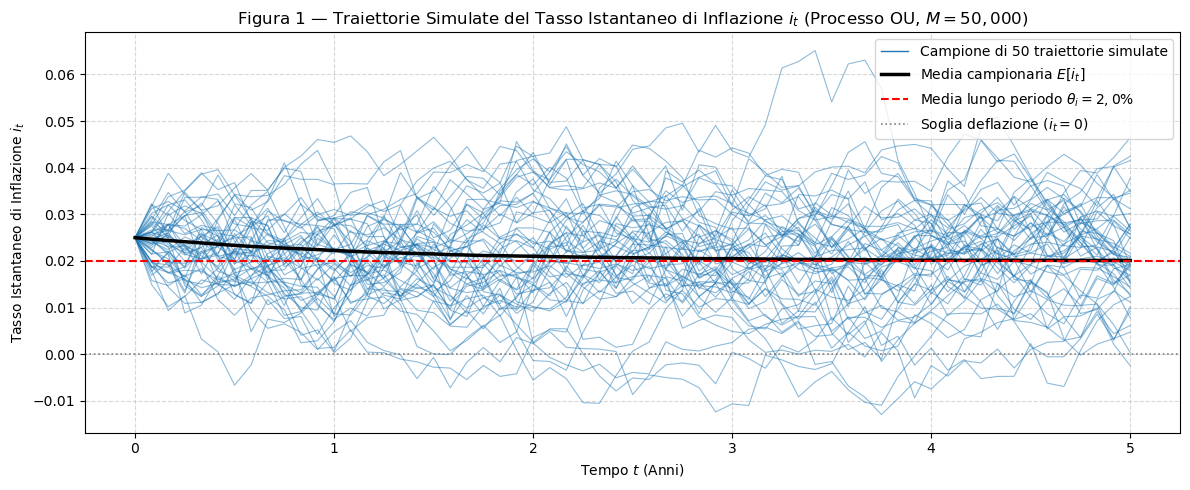

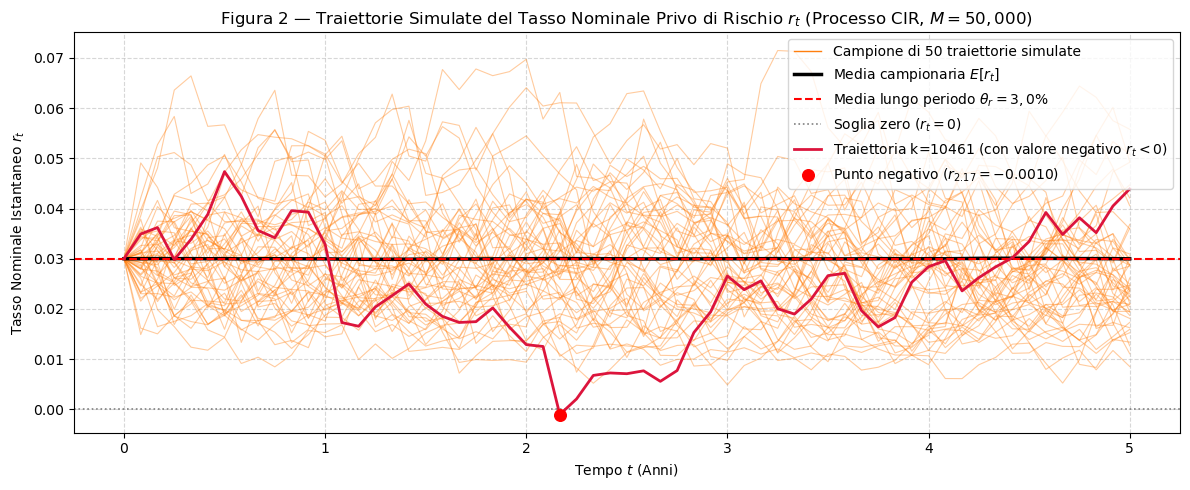

In [20]:
# ==============================================================================
# TAPPA 2: GENERAZIONE SHOCK CORRELATI E SIMULAZIONE TRAIETTORIE DEI TASSI
# (Versione aggiornata con evidenziazione traiettoria CIR negativa e legenda 50 traiettorie)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 2.1 Generazione degli Shock Normali Correlati
# ------------------------------------------------------------------------------

# Impostazione del seme per la riproducibilità
np.random.seed(seed)

# Generazione di due matrici di variabili normali standard indipendenti (M x N_steps)
Z1 = np.random.normal(0.0, 1.0, size=(M, N_steps))
Z2 = np.random.normal(0.0, 1.0, size=(M, N_steps))

# Decomposizione di Cholesky / combinazione lineare per introdurre la correlazione rho
Z_i = Z1
Z_r = rho * Z1 + np.sqrt(1.0 - rho**2) * Z2

# ------------------------------------------------------------------------------
# 2.2 Simulazione Passo-Passo delle Traiettorie (OU per i_t, CIR per r_t)
# ------------------------------------------------------------------------------

# Inizializzazione delle matrici delle traiettorie (M x (N_steps + 1))
i_sim = np.zeros((M, N_steps + 1))
r_sim = np.zeros((M, N_steps + 1))

# Condizioni iniziali a t = 0
i_sim[:, 0] = i_0
r_sim[:, 0] = r_0

sqrt_dt = np.sqrt(dt)

# Simulazione sequenziale lungo la griglia temporale
for step in range(N_steps):
    # Valori al tempo corrente t
    i_curr = i_sim[:, step]
    r_curr = r_sim[:, step]
    
    # Shock al passo corrente
    z_i_curr = Z_i[:, step]
    z_r_curr = Z_r[:, step]
    
    # Processo OU per l'inflazione i_t (consente valori negativi)
    di = kappa_i * (theta_i - i_curr) * dt + sigma_i * sqrt_dt * z_i_curr
    i_sim[:, step + 1] = i_curr + di
    
    # Processo CIR per il tasso nominale r_t
    # Troncamento max(r_curr, 0) applicato solo sotto radice quadrata nel termine diffusivo
    r_pos = np.maximum(r_curr, 0.0)
    dr = kappa_r * (theta_r - r_curr) * dt + sigma_r * np.sqrt(r_pos) * sqrt_dt * z_r_curr
    r_sim[:, step + 1] = r_curr + dr

# ------------------------------------------------------------------------------
# 2.3 Esecuzione dei Controlli Richiesti (Controllo 1 e Controllo 4)
# ------------------------------------------------------------------------------

print("=" * 80)
print("CONTROLLI E DIAGNOSTICA DELLA SIMULAZIONE (TAPPA 2)")
print("=" * 80)

# Controllo 1: Correlazione empirica degli shock generati
rho_empirica = np.corrcoef(Z_i.ravel(), Z_r.ravel())[0, 1]
diff_rho = abs(rho_empirica - rho)

print("1. CONTROLLO 1 — Correlazione Empirica degli Shock Stocastici:")
print(f"   Correlazione teorica  (rho):       {rho:.6f}")
print(f"   Correlazione empirica (rho_emp):   {rho_empirica:.6f}")
print(f"   Scostamento assoluto:              {diff_rho:.6f}")
print(f"   Esito: Coerente con la specifica (rho = 0.25)? -> {diff_rho < 1e-2}")

# Controllo 4: Rilevazione e documentazione di tassi nominali negativi (r_t < 0)
indici_negativi = np.where(r_sim < 0.0)
num_valori_negativi = len(indici_negativi[0])
totale_punti_griglia = M * (N_steps + 1)
pct_valori_negativi = (num_valori_negativi / totale_punti_griglia) * 100.0

print("\n2. CONTROLLO 4 — Rilevazione Tassi Nominali Negativi (CIR):")
print(f"   Totale valutazioni sulla griglia (M x (N_steps+1)): {totale_punti_griglia:,}".replace(",", "."))
print(f"   Numero di valori r_t < 0 rilevati:                {num_valori_negativi:,}".replace(",", "."))
print(f"   Percentuale sul totale delle valutazioni:         {pct_valori_negativi:.4f}%")

# Individuazione della prima replica con valore negativo per l'evidenziazione nel grafico
if num_valori_negativi > 0:
    idx_replica_negativa = indici_negativi[0][0]
    passo_negativo = indici_negativi[1][0]
    tempo_negativo = t_grid[passo_negativo]
    valore_negativo = r_sim[idx_replica_negativa, passo_negativo]
    print(f"   Esempio rilevato -> Replica k={idx_replica_negativa}, passo t={tempo_negativo:.2f} anni, r_t={valore_negativo:.6f}")
else:
    idx_replica_negativa = None

print("=" * 80)

# ------------------------------------------------------------------------------
# 2.4 Generazione dei Grafici Richiesti (Figura 1 e Figura 2)
# ------------------------------------------------------------------------------

n_traiettorie_plot = 50  # Numero di traiettorie da mostrare nei grafici

# Figura 1: Traiettorie simulate del tasso di inflazione i_t
plt.figure(figsize=(12, 5))
plt.plot(t_grid, i_sim[:n_traiettorie_plot, :].T, lw=0.8, alpha=0.5, color='tab:blue')
plt.plot([], [], color='tab:blue', lw=1.0, label=f'Campione di {n_traiettorie_plot} traiettorie simulate')
plt.plot(t_grid, np.mean(i_sim, axis=0), color='black', lw=2.5, label='Media campionaria $E[i_t]$')
plt.axhline(theta_i, color='red', linestyle='--', lw=1.5, label=r'Media lungo periodo $\theta_i = 2,0\%$')
plt.axhline(0.0, color='gray', linestyle=':', lw=1.2, label='Soglia deflazione ($i_t = 0$)')
plt.title(f'Figura 1 — Traiettorie Simulate del Tasso Istantaneo di Inflazione $i_t$ (Processo OU, $M={M:,}$)', fontsize=12)
plt.xlabel('Tempo $t$ (Anni)', fontsize=10)
plt.ylabel('Tasso Istantaneo di Inflazione $i_t$', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# Figura 2: Traiettorie simulate del tasso nominale r_t
plt.figure(figsize=(12, 5))
plt.plot(t_grid, r_sim[:n_traiettorie_plot, :].T, lw=0.8, alpha=0.4, color='tab:orange')
plt.plot([], [], color='tab:orange', lw=1.0, label=f'Campione di {n_traiettorie_plot} traiettorie simulate')
plt.plot(t_grid, np.mean(r_sim, axis=0), color='black', lw=2.5, label='Media campionaria $E[r_t]$')
plt.axhline(theta_r, color='red', linestyle='--', lw=1.5, label=r'Media lungo periodo $\theta_r = 3,0\%$')
plt.axhline(0.0, color='gray', linestyle=':', lw=1.2, label='Soglia zero ($r_t = 0$)')

# Evidenziazione della traiettoria con valore negativo se presente
if idx_replica_negativa is not None:
    plt.plot(t_grid, r_sim[idx_replica_negativa, :], color='crimson', lw=2.0, 
             label=f'Traiettoria k={idx_replica_negativa} (con valore negativo $r_t < 0$)')
    plt.scatter([tempo_negativo], [valore_negativo], color='red', s=70, zorder=5, 
                label=f'Punto negativo ($r_{{{tempo_negativo:.2f}}} = {valore_negativo:.4f}$)')

plt.title(f'Figura 2 — Traiettorie Simulate del Tasso Nominale Privo di Rischio $r_t$ (Processo CIR, $M={M:,}$)', fontsize=12)
plt.xlabel('Tempo $t$ (Anni)', fontsize=10)
plt.ylabel('Tasso Nominale Istantaneo $r_t$', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# Tappa 3 — Calcolo dei Fattori Stocastici di Indicizzazione e di Sconto

## Copia Fedele della Richiesta dello Studente
> Sto lavorando sulla Tappa 3 della scomposizione input-output.
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output:
> - una cella Markdown descrittiva della tappa, degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva
> - una cella Python che esegua questa tappa

---

## Sintesi Logica della Tappa 3

- **Obiettivo:** Trasformare le traiettorie simulate dei tassi istantanei $(i_t, r_t)$ nei rispettivi fattori stocastici per ogni replica $k$ lungo l'intera griglia temporale:
  1. Fattore stocastico cumulato di indicizzazione $J_t^{(k)} = \frac{I_t^{(k)}}{I_0} = \exp\left( \int_0^t i_s^{(k)} ds \right)$
  2. Fattore di sconto stocastico $D^{(k)}(0, t) = \exp\left( -\int_0^t r_s^{(k)} ds \right)$
  Inoltre, calcolare le statistiche descrittive delle variabili terminali a scadenza $T=5$ ed elaborare gli output analitici correlati.
- **Input:** Matrici delle traiettorie simulate `i_sim` e `r_sim` di dimensione $(M \times (N_{steps}+1))$, griglia temporale `t_grid`, passo di discretizzazione $\Delta t = 1/12$, numero di repliche $M = 50.000$.
- **Operazioni:**
  1. Integrazione numerica cumulata del tasso di inflazione $i_t^{(k)}$ lungo ciascuna traiettoria mediante la regola rettangolare (somma cumulata):
     $$J_t^{(k)} = \exp\left( \sum_{s=1}^{t/\Delta t} i_s^{(k)} \Delta t \right), \quad \text{con } J_0^{(k)} = 1.0$$
  2. Integrazione numerica cumulata del tasso nominale $r_t^{(k)}$ lungo ciascuna traiettoria:
     $$D^{(k)}(0, t) = \exp\left( -\sum_{s=1}^{t/\Delta t} r_s^{(k)} \Delta t \right), \quad \text{con } D^{(k)}(0, 0) = 1.0$$
  3. Estrazione dei valori terminali a $T=5$ anni ($i_T, r_T, J_T$) per tutte le $M$ repliche.
  4. Calcolo di media e deviazione standard campionaria di $i_T$, $r_T$ e $J_T$ per la compilazione della **Tabella 4**.
  5. Costruzione della distribuzione di frequenza del fattore di indicizzazione terminale $J_T$ (**Figura 3**).
- **Output:**
  - **Tabella 4:** Tabella delle statistiche terminali di $i_T$, $r_T$ e $J_T$ (media e deviazione standard).
  - **Figura 3:** Grafico dell'istogramma/densità della distribuzione simulata di $J_T$ con evidenziazione della soglia unitaria di floor ($J_T = 1.0$).
  - Matrici in memoria: `J_sim` e `D_sim` di dimensione $(M \times (N_{steps}+1))$.
- **Controlli:**
  - **Controllo 2 (Positività del fattore di indicizzazione):** Verifica rigorosa che $J_{t_j}^{(k)} > 0$ per ciascuna replica $k$ e per ciascun passo temporale $t_j$.
- **Legame con la Tappa Precedente e Successiva:**
  - *Dalla Tappa 2:* Riceve le matrici `i_sim` e `r_sim` contenenti le traiettorie simulate dei fattori di rischio.
  - *Verso la Tappa 4:* Le matrici `J_sim` e `D_sim` (estratte in corrispondenza delle date di stacco cedolare semestrali $t_j$ e della scadenza $T$) costituiscono l'input diretto per la determinazione delle cedole stocastiche $C_{t_j}^{(k)}$, del capitale protetto da floor $R_T^{(k)}$ e dei relativi valori attuali lungo ciascuna replica Monte Carlo.

CONTROLLI E DIAGNOSTICA DEI FATTORI STOCASTICI (TAPPA 3)
1. CONTROLLO 2 — Positività del Fattore di Indicizzazione J_t:
   Valore minimo registrato di J_t su tutte le M x (N_steps+1) valutazioni: 0.969701
   Esito: J_t^(k) > 0 per ogni replica e data? -> True

TABELLA 4: STATISTICHE TERMINALI DI i_T, r_T E J_T (t = 5 Anni)


,Variabile Terminale,Media Simulata,Deviazione Standard Simulata,Valore Teorico / Atteso
0,Tasso Istantaneo di Inflazione ($i_T$),0.020101 (2.010%),0.012119 (1.212%),0.020092 (2.000% asint.)
1,Tasso Nominale Istantaneo ($r_T$),0.029982 (2.998%),0.011447 (1.145%),0.030000 (3.000% asint.)
2,Fattore Cumulato di Indicizzazione ($J_T$),1.112367,0.037578,1.112592 (Log-Normale esatta)


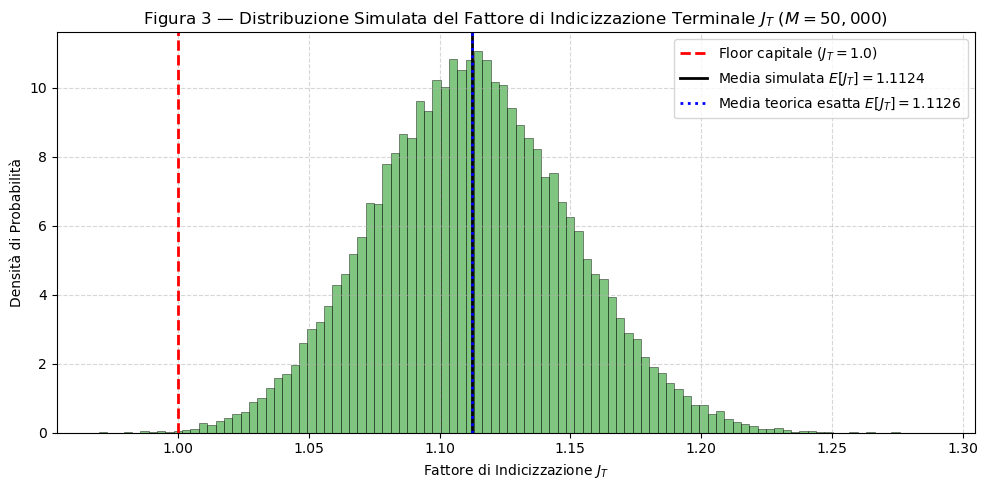

In [23]:
# ==============================================================================
# TAPPA 3: CALCOLO DEI FATTORI STOCASTICI DI INDICIZZAZIONE E DI SCONTO
# (Versione aggiornata con valore teorico esatto log-normale per E[J_T])
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 3.1 Approssimazione Numerica degli Integrali Cumulati (Regola Rettangolare)
# ------------------------------------------------------------------------------

# Inizializzazione delle matrici dei fattori stocastici (M x (N_steps + 1))
J_sim = np.ones((M, N_steps + 1))
D_sim = np.ones((M, N_steps + 1))

# Somma cumulata integrata lungo l'asse temporale (asse 1) per ciascuna replica
# Integrale di i_s da 0 a t: sum_{s=1}^{t} i_s * dt
int_i = np.cumsum(i_sim[:, 1:] * dt, axis=1)
J_sim[:, 1:] = np.exp(int_i)

# Integrale di r_s da 0 a t: sum_{s=1}^{t} r_s * dt
int_r = np.cumsum(r_sim[:, 1:] * dt, axis=1)
D_sim[:, 1:] = np.exp(-int_r)

# ------------------------------------------------------------------------------
# 3.2 Esecuzione dei Controlli Richiesti (Controllo 2)
# ------------------------------------------------------------------------------

print("=" * 80)
print("CONTROLLI E DIAGNOSTICA DEI FATTORI STOCASTICI (TAPPA 3)")
print("=" * 80)

# Controllo 2: Positività del fattore di indicizzazione J_t per ogni replica e data
min_J = np.min(J_sim)
tutti_positivi_J = min_J > 0.0

print("1. CONTROLLO 2 — Positività del Fattore di Indicizzazione J_t:")
print(f"   Valore minimo registrato di J_t su tutte le M x (N_steps+1) valutazioni: {min_J:.6f}")
print(f"   Esito: J_t^(k) > 0 per ogni replica e data? -> {tutti_positivi_J}")
print("=" * 80)

# ------------------------------------------------------------------------------
# 3.3 Calcolo Teorico Esatto per E[J_T] (Log-Normale da Processo OU Integrato)
# ------------------------------------------------------------------------------

# 1. Media dell'integrale dell'inflazione X_T = int_0^T i_t dt
mu_X_T = theta_i * T + (i_0 - theta_i) * (1.0 - np.exp(-kappa_i * T)) / kappa_i

# 2. Varianza dell'integrale dell'inflazione Var(X_T)
var_X_T = (sigma_i**2 / kappa_i**2) * (
    T - (2.0 / kappa_i) * (1.0 - np.exp(-kappa_i * T)) + (1.0 / (2.0 * kappa_i)) * (1.0 - np.exp(-2.0 * kappa_i * T))
)

# 3. Valore atteso esatto log-normale E[J_T] = exp(mu_X + 0.5 * var_X)
E_J_T_teorico_esatto = np.exp(mu_X_T + 0.5 * var_X_T)

# ------------------------------------------------------------------------------
# 3.4 Calcolo delle Statistiche Terminali a T = 5 e TABELLA 4
# ------------------------------------------------------------------------------

# Estrazione delle variabili terminali al passo N_steps (t = T = 5 anni)
i_T = i_sim[:, -1]
r_T = r_sim[:, -1]
J_T = J_sim[:, -1]

# Calcolo di medie e deviazioni standard campionarie
statistiche_terminali = [
    {
        "Variabile Terminale": "Tasso Istantaneo di Inflazione ($i_T$)",
        "Media Simulata": f"{np.mean(i_T):.6f} ({np.mean(i_T)*100:.3f}%)",
        "Deviazione Standard Simulata": f"{np.std(i_T, ddof=1):.6f} ({np.std(i_T, ddof=1)*100:.3f}%)",
        "Valore Teorico / Atteso": f"{theta_i + (i_0 - theta_i)*np.exp(-kappa_i*T):.6f} ({theta_i*100:.3f}% asint.)"
    },
    {
        "Variabile Terminale": "Tasso Nominale Istantaneo ($r_T$)",
        "Media Simulata": f"{np.mean(r_T):.6f} ({np.mean(r_T)*100:.3f}%)",
        "Deviazione Standard Simulata": f"{np.std(r_T, ddof=1):.6f} ({np.std(r_T, ddof=1)*100:.3f}%)",
        "Valore Teorico / Atteso": f"{theta_r + (r_0 - theta_r)*np.exp(-kappa_r*T):.6f} ({theta_r*100:.3f}% asint.)"
    },
    {
        "Variabile Terminale": "Fattore Cumulato di Indicizzazione ($J_T$)",
        "Media Simulata": f"{np.mean(J_T):.6f}",
        "Deviazione Standard Simulata": f"{np.std(J_T, ddof=1):.6f}",
        "Valore Teorico / Atteso": f"{E_J_T_teorico_esatto:.6f} (Log-Normale esatta)"
    }
]

df_tabella_4 = pd.DataFrame(statistiche_terminali)

print("\n" + "=" * 80)
print("TABELLA 4: STATISTICHE TERMINALI DI i_T, r_T E J_T (t = 5 Anni)")
print("=" * 80)
display(df_tabella_4)

# ------------------------------------------------------------------------------
# 3.5 Generazione del Grafico Richiesto (Figura 3)
# ------------------------------------------------------------------------------

plt.figure(figsize=(10, 5))
count, bins, ignored = plt.hist(J_T, bins=100, density=True, alpha=0.6, color='tab:green', edgecolor='black', linewidth=0.5)
plt.axvline(1.0, color='red', linestyle='--', lw=2.0, label='Floor capitale ($J_T = 1.0$)')
plt.axvline(np.mean(J_T), color='black', linestyle='-', lw=2.0, label=f'Media simulata $E[J_T] = {np.mean(J_T):.4f}$')
plt.axvline(E_J_T_teorico_esatto, color='blue', linestyle=':', lw=2.0, label=f'Media teorica esatta $E[J_T] = {E_J_T_teorico_esatto:.4f}$')

plt.title(f'Figura 3 — Distribuzione Simulata del Fattore di Indicizzazione Terminale $J_T$ ($M={M:,}$)', fontsize=12)
plt.xlabel('Fattore di Indicizzazione $J_T$', fontsize=10)
plt.ylabel('Densità di Probabilità', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# Tappa 4 — Determinazione dei Flussi di Cassa e Attualizzazione Percorso per Percorso

## Copia Fedele della Richiesta dello Studente
> Sto lavorando sulla Tappa 4 della scomposizione input-output.
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output:
> - una cella Markdown descrittiva della tappa, degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva
> - una cella Python che esegua questa tappa

---

## Sintesi Logica della Tappa 4

- **Obiettivo:** Determinare i flussi di cassa contrattuali (cedole stocastiche semestrali e rimborso del capitale a scadenza protetto da floor) per ciascuna replica Monte Carlo $k$, calcolare i relativi valori attuali lungo ciascuna traiettoria e stimare la probabilità di deflazione cumulata a scadenza.
- **Input:** Matrici dei fattori stocastici `J_sim` e `D_sim` (da Tappa 3), indici delle date cedolari `coupon_step_indices` (da Tappa 1), parametri contrattuali ($N = 100$, $c = 1,5\%$ annuo, frequenza semestrale, $T = 5$ anni, $M = 50.000$).
- **Operazioni:**
  1. Estrazione del fattore di indicizzazione $J_{t_j}^{(k)}$ in corrispondenza delle 10 date cedolari semestrali $t_j \in \{0.5, 1.0, \dots, 5.0\}$ e del fattore di sconto stocastico $D^{(k)}(0, t_j)$ per ogni replica $k$.
  2. Calcolo della cedola stocastica semestrale non protetta per ogni replica $k$ e data $t_j$:
     $$C_{t_j}^{(k)} = \frac{c}{2} N J_{t_j}^{(k)}$$
  3. Calcolo del valore attuale delle cedole lungo la replica $k$:
     $$PV_C^{(k)} = \sum_{j=1}^{10} D^{(k)}(0, t_j) C_{t_j}^{(k)}$$
  4. Calcolo del capitale rimborsato a scadenza con floor nominale per ogni replica $k$:
     $$R_T^{(k)} = N \max\left(J_T^{(k)}, 1.0\right)$$
  5. Calcolo del valore attuale del rimborso del capitale lungo la replica $k$:
     $$PV_R^{(k)} = D^{(k)}(0, T) R_T^{(k)}$$
  6. Calcolo del valore attuale totale del titolo per ciascuna replica $k$:
     $$V^{(k)} = PV_C^{(k)} + PV_R^{(k)}$$
  7. Stima della **probabilità simulata di deflazione cumulata a scadenza**:
     $$\widehat{\mathbb{P}}(J_T < 1) = \frac{1}{M} \sum_{k=1}^M \mathbf{1}_{\{J_T^{(k)} < 1.0\}}$$
  8. Generazione della **Figura 4** (distribuzione dei valori attuali $V^{(k)}$).
- **Output:**
  - **Figura 4:** Istogramma e densità empirica dei valori attuali $V^{(k)}$ con indicazione del valore medio campionario.
  - Vettori in memoria di dimensione $M$: `pv_coupons_k`, `pv_redemption_k`, `v_k`.
  - **Quantità da stimare 5:** Probabilità di deflazione cumulata a scadenza $\widehat{\mathbb{P}}(J_T < 1)$.
- **Controlli:**
  - **Controllo 3 (Rispetto del floor sul capitale):** Verifica che $R_T^{(k)} \geq N$ per tutte le $M = 50.000$ repliche (ovvero $\min(R_T^{(k)}) \geq 100$).
- **Legame con la Tappa Precedente e Successiva:**
  - *Dalla Tappa 3:* Riceve le matrici dei fattori stocastici `J_sim` e `D_sim`.
  - *Verso la Tappa 5:* I vettori `pv_coupons_k`, `pv_redemption_k` e `v_k` costituiscono l'input diretto per calcolare le medie campionarie $(\widehat{PV}_C, \widehat{PV}_R, \widehat{V}_M)$, l'errore standard $SE(\widehat{V}_M)$, l'intervallo di confidenza al 95% e la compilazione della **Tabella 2 (Sintesi del Pricing)**.

CONTROLLI E DIAGNOSTICA SUI FLUSSI E VALORI ATTUALI (TAPPA 4)
1. CONTROLLO 3 — Rispetto del Floor sul Capitale (R_T >= N):
   Valore facciale N:                           100.00
   Valore minimo di R_T registrato tra le M repliche: 100.000000
   Esito: R_T^(k) >= N per tutte le 50.000 repliche? -> True

2. QUANTITÀ DA STIMARE 5 — Probabilità Simulata di Deflazione Cumulata a Scadenza:
   Numero di repliche con J_T < 1.0:            37 su 50.000
   Probabilità di deflazione P(J_T < 1.0):     0.000740 (0.074%)


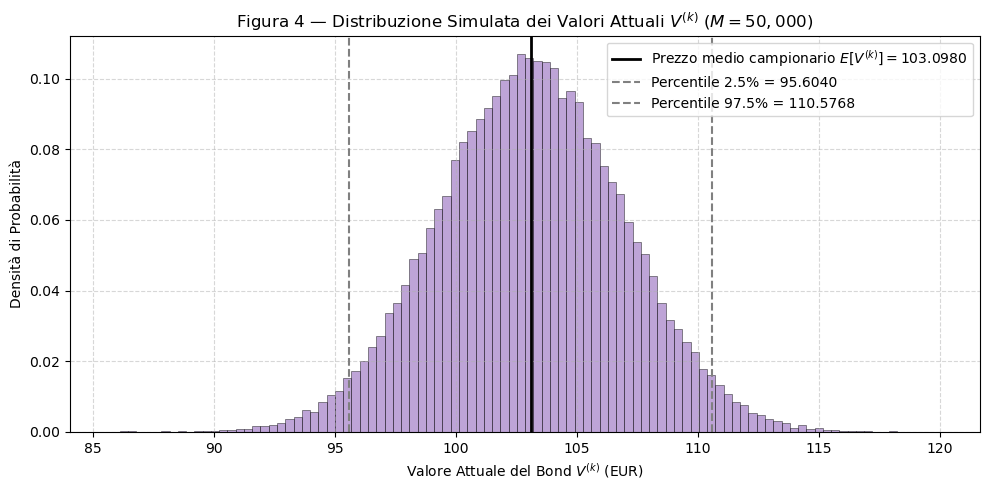

In [25]:
# ==============================================================================
# TAPPA 4: DETERMINAZIONE FLUSSI DI CASSA E ATTUALIZZAZIONE PERCORSO PER PERCORSO
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 4.1 Estrazione dei Fattori Stocastici alle Date Cedolari e a Scadenza
# ------------------------------------------------------------------------------

# Estrazione delle matrici M x 10 per le date di stacco cedolare semestrali
J_coupons = J_sim[:, coupon_step_indices]      # Fattore indicizzazione alle date t_j
D_coupons = D_sim[:, coupon_step_indices]      # Fattore sconto alle date t_j

# Estrazione dei fattori stocastici a scadenza T = 5 (ultimo passo temporale)
J_T_vec = J_sim[:, -1]
D_T_vec = D_sim[:, -1]

# ------------------------------------------------------------------------------
# 4.2 Calcolo dei Flussi di Cassa e Valori Attuali per Ciascuna Replica k
# ------------------------------------------------------------------------------

# Cedole stocastiche semestrali per ogni replica k e data t_j (M x 10)
C_tj = (c / freq_cedole) * N * J_coupons

# Valore attuale delle cedole per ciascuna replica k (vettore lungo M)
pv_coupons_k = np.sum(D_coupons * C_tj, axis=1)

# Capitale rimborsato a scadenza con floor nominale (vettore lungo M)
# R_T = N * max(J_T, 1.0)
R_T_k = N * np.maximum(J_T_vec, 1.0)

# Valore attuale del rimborso del capitale per ciascuna replica k (vettore lungo M)
pv_redemption_k = D_T_vec * R_T_k

# Valore attuale totale del titolo per ciascuna replica k (vettore lungo M)
v_k = pv_coupons_k + pv_redemption_k

# ------------------------------------------------------------------------------
# 4.3 Quantità da Stimare 5: Probabilità Simulata di Deflazione Cumulata a Scadenza
# ------------------------------------------------------------------------------

# Probabilita' empirica P(J_T < 1.0)
deflation_events = J_T_vec < 1.0
p_deflation = np.mean(deflation_events)
num_deflation_cases = np.sum(deflation_events)

# ------------------------------------------------------------------------------
# 4.4 Esecuzione dei Controlli Richiesti (Controllo 3)
# ------------------------------------------------------------------------------

print("=" * 80)
print("CONTROLLI E DIAGNOSTICA SUI FLUSSI E VALORI ATTUALI (TAPPA 4)")
print("=" * 80)

# Controllo 3: Rimborso R_T >= N su tutte le repliche
min_R_T = np.min(R_T_k)
floor_respected = min_R_T >= N

print("1. CONTROLLO 3 — Rispetto del Floor sul Capitale (R_T >= N):")
print(f"   Valore facciale N:                           {N:.2f}")
print(f"   Valore minimo di R_T registrato tra le M repliche: {min_R_T:.6f}")
print(f"   Esito: R_T^(k) >= N per tutte le {M:,} repliche? -> {floor_respected}".replace(",", "."))

print("\n2. QUANTITÀ DA STIMARE 5 — Probabilità Simulata di Deflazione Cumulata a Scadenza:")
print(f"   Numero di repliche con J_T < 1.0:            {num_deflation_cases:,} su {M:,}".replace(",", "."))
print(f"   Probabilità di deflazione P(J_T < 1.0):     {p_deflation:.6f} ({p_deflation*100:.3f}%)")
print("=" * 80)

# ------------------------------------------------------------------------------
# 4.5 Generazione del Grafico Richiesto (Figura 4) - CORRETTO
# ------------------------------------------------------------------------------

plt.figure(figsize=(10, 5))
count, bins, ignored = plt.hist(v_k, bins=100, density=True, alpha=0.6, color='tab:purple', edgecolor='black', linewidth=0.5)

# Nota: raddoppiate le graffe {{k}} per LaTeX dentro la f-string
plt.axvline(np.mean(v_k), color='black', linestyle='-', lw=2.0, label=f'Prezzo medio campionario $E[V^{{(k)}}] = {np.mean(v_k):.4f}$')
plt.axvline(np.percentile(v_k, 2.5), color='gray', linestyle='--', lw=1.5, label=f'Percentile 2.5% = {np.percentile(v_k, 2.5):.4f}')
plt.axvline(np.percentile(v_k, 97.5), color='gray', linestyle='--', lw=1.5, label=f'Percentile 97.5% = {np.percentile(v_k, 97.5):.4f}')

plt.title(f'Figura 4 — Distribuzione Simulata dei Valori Attuali $V^{{(k)}}$ ($M={M:,}$)', fontsize=12)
plt.xlabel('Valore Attuale del Bond $V^{(k)}$ (EUR)', fontsize=10)
plt.ylabel('Densità di Probabilità', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# Tappa 5 — Stima Monte Carlo del Prezzo, Diagnostica di Precisione e Decomposizione

## Copia Fedele della Richiesta dello Studente
> Sto lavorando sulla Tappa 5 della scomposizione input-output.
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output:
> - una cella Markdown descrittiva della tappa, degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva
> - una cella Python che esegua questa tappa

---

## Sintesi Logica della Tappa 5

- **Obiettivo:** Calcolare la stima Monte Carlo del prezzo corrente del bond $\widehat{V}_M$, la decomposizione del prezzo nelle sue due componenti trasversali (valore attuale medio delle cedole $\widehat{PV}_C$ e valore attuale medio del rimborso del capitale $\widehat{PV}_R$), l'errore standard campionario $SE(\widehat{V}_M)$ e il relativo intervallo di confidenza al 95%.
- **Input:** Vettori dei valori attuali per replica `pv_coupons_k`, `pv_redemption_k` e `v_k` di dimensione $M = 50.000$ (da Tappa 4), numero di repliche Monte Carlo $M = 50.000$.
- **Operazioni:**
  1. Calcolo del valore attuale medio campionario delle cedole:
     $$\widehat{PV}_C = \frac{1}{M} \sum_{k=1}^M PV_C^{(k)}$$
  2. Calcolo del valore attuale medio campionario del rimborso del capitale:
     $$\widehat{PV}_R = \frac{1}{M} \sum_{k=1}^M PV_R^{(k)}$$
  3. Calcolo del prezzo Monte Carlo del bond:
     $$\widehat{V}_M = \frac{1}{M} \sum_{k=1}^M V^{(k)}$$
  4. Calcolo della deviazione standard campionaria corretta $s_V$ dei valori attuali totali $V^{(k)}$.
  5. Calcolo dell'errore standard Monte Carlo del prezzo:
     $$SE(\widehat{V}_M) = \frac{s_V}{\sqrt{M}}$$
  6. Calcolo dell'intervallo di confidenza al 95% per la stima del prezzo:
     $$\text{IC}_{95\%} = \left[ \widehat{V}_M - 1,96 \, SE(\widehat{V}_M), \; \widehat{V}_M + 1,96 \, SE(\widehat{V}_M) \right]$$
  7. Formattazione e visualizzazione della **Tabella 2 (Tabella di Sintesi del Pricing)** mediante `pandas.DataFrame`.
- **Output:**
  - **Tabella 2:** Tabella di sintesi del pricing contenente valore attuale medio delle cedole, valore attuale medio del rimborso, prezzo Monte Carlo del bond, deviazione standard campionaria, errore standard e intervallo di confidenza al 95%.
  - Scalari in memoria: `V_hat_M`, `PV_C_hat`, `PV_R_hat`, `s_V`, `SE_V_hat`, `ci_lower`, `ci_upper`.
- **Controlli:**
  - **Controllo 5 (Decomposizione del prezzo):** Verifica dell'identità contabile ed aritmetica esatta $\widehat{V}_M = \widehat{PV}_C + \widehat{PV}_R$.
- **Legame con la Tappa Precedente e Successiva:**
  - *Dalla Tappa 4:* Riceve i vettori `pv_coupons_k`, `pv_redemption_k` e `v_k`.
  - *Verso la Tappa 6:* Il vettore dei valori attuali `v_k` costituisce l'input per condurre l'analisi di convergenza Monte Carlo al variare di $M \in \{1.000, 5.000, 10.000, 50.000\}$ (**Tabella 3** e **Figura 5**) e verificare il tasso di riduzione dell'errore standard.

In [27]:
# ==============================================================================
# TAPPA 5: STIMA MONTE CARLO DEL PREZZO, ERRORE STANDARD E DECOMPOSIZIONE
# ==============================================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 5.1 Calcolo delle Stime Campionarie delle Componenti del Prezzo
# ------------------------------------------------------------------------------

# Valore attuale medio delle cedole PV_C_hat
PV_C_hat = np.mean(pv_coupons_k)

# Valore attuale medio del rimborso del capitale PV_R_hat
PV_R_hat = np.mean(pv_redemption_k)

# Prezzo Monte Carlo stimato V_hat_M
V_hat_M = np.mean(v_k)

# Deviazione standard campionaria corretta dei valori attuali V^(k) (ddof=1)
s_V = np.std(v_k, ddof=1)

# Errore Standard Monte Carlo del prezzo
SE_V_hat = s_V / np.sqrt(M)

# Intervallo di confidenza al 95% (z = 1.96)
z_95 = 1.96
ci_lower = V_hat_M - z_95 * SE_V_hat
ci_upper = V_hat_M + z_95 * SE_V_hat

# ------------------------------------------------------------------------------
# 5.2 Esecuzione dei Controlli Richiesti (Controllo 5)
# ------------------------------------------------------------------------------

print("=" * 80)
print("CONTROLLI E DIAGNOSTICA DEL PRICING MONTE CARLO (TAPPA 5)")
print("=" * 80)

# Controllo 5: Decomposizione V_hat_M = PV_C_hat + PV_R_hat
somma_componenti = PV_C_hat + PV_R_hat
diff_decomposizione = abs(V_hat_M - somma_componenti)
decomposizione_valida = np.isclose(V_hat_M, somma_componenti)

print("1. CONTROLLO 5 — Decomposizione del Prezzo Monte Carlo (V_hat = PV_C + PV_R):")
print(f"   Valore Attuale Medio Cedole  (PV_C_hat): {PV_C_hat:.6f} EUR")
print(f"   Valore Attuale Medio Rimborso (PV_R_hat): {PV_R_hat:.6f} EUR")
print(f"   Somma delle due componenti:              {somma_componenti:.6f} EUR")
print(f"   Prezzo Monte Carlo stimato   (V_hat_M):   {V_hat_M:.6f} EUR")
print(f"   Scostamento assoluto:                     {diff_decomposizione:.2e} EUR")
print(f"   Esito: Decomposizione soddisfatta in modo esatto? -> {decomposizione_valida}")
print("=" * 80)

# ------------------------------------------------------------------------------
# 5.3 Generazione della TABELLA 2: Tabella di Sintesi del Pricing
# ------------------------------------------------------------------------------

sintesi_pricing_data = [
    {
        "Componente / Metrica": "Valore Attuale Medio Cedole ($\\widehat{PV}_C$)",
        "Stima Puntuale (EUR)": f"{PV_C_hat:.4f}",
        "Incidenza % sul Prezzo": f"{(PV_C_hat / V_hat_M) * 100:.2f}%",
        "Note": "Somma attualizzata delle cedole semestrali indicizzate"
    },
    {
        "Componente / Metrica": "Valore Attuale Medio Rimborso ($\\widehat{PV}_R$)",
        "Stima Puntuale (EUR)": f"{PV_R_hat:.4f}",
        "Incidenza % sul Prezzo": f"{(PV_R_hat / V_hat_M) * 100:.2f}%",
        "Note": "Capitale rimborsato a scadenza con floor $R_T \\ge N$"
    },
    {
        "Componente / Metrica": "Prezzo Monte Carlo Bond ($\\widehat{V}_M$)",
        "Stima Puntuale (EUR)": f"{V_hat_M:.4f}",
        "Incidenza % sul Prezzo": "100.00%",
        "Note": "Valore stimato del titolo su $M = 50.000$ repliche"
    },
    {
        "Componente / Metrica": "Deviazione Standard Campionaria ($s_V$)",
        "Stima Puntuale (EUR)": f"{s_V:.4f}",
        "Incidenza % sul Prezzo": "-",
        "Note": "Variabilità dei valori attuali $V^{(k)}$ tra le repliche"
    },
    {
        "Componente / Metrica": "Errore Standard Monte Carlo ($SE$)",
        "Stima Puntuale (EUR)": f"{SE_V_hat:.6f}",
        "Incidenza % sul Prezzo": f"{(SE_V_hat / V_hat_M) * 100:.4f}%",
        "Note": "Precisione numerica della stima ($s_V / \\sqrt{M}$)"
    },
    {
        "Componente / Metrica": "Intervallo Confidenza 95% (Inferiore)",
        "Stima Puntuale (EUR)": f"{ci_lower:.4f}",
        "Incidenza % sul Prezzo": "-",
        "Note": "$\\widehat{V}_M - 1,96 \\cdot SE$"
    },
    {
        "Componente / Metrica": "Intervallo Confidenza 95% (Superiore)",
        "Stima Puntuale (EUR)": f"{ci_upper:.4f}",
        "Incidenza % sul Prezzo": "-",
        "Note": "$\\widehat{V}_M + 1,96 \\cdot SE$"
    }
]

df_tabella_2 = pd.DataFrame(sintesi_pricing_data)

print("\n" + "=" * 80)
print("TABELLA 2: TABELLA DI SINTESI DEL PRICING")
print("=" * 80)
display(df_tabella_2)

CONTROLLI E DIAGNOSTICA DEL PRICING MONTE CARLO (TAPPA 5)
1. CONTROLLO 5 — Decomposizione del Prezzo Monte Carlo (V_hat = PV_C + PV_R):
   Valore Attuale Medio Cedole  (PV_C_hat): 7.335290 EUR
   Valore Attuale Medio Rimborso (PV_R_hat): 95.762735 EUR
   Somma delle due componenti:              103.098025 EUR
   Prezzo Monte Carlo stimato   (V_hat_M):   103.098025 EUR
   Scostamento assoluto:                     1.42e-14 EUR
   Esito: Decomposizione soddisfatta in modo esatto? -> True

TABELLA 2: TABELLA DI SINTESI DEL PRICING


,Componente / Metrica,Stima Puntuale (EUR),Incidenza % sul Prezzo,Note
0,Valore Attuale Medio Cedole ($\widehat{PV}_C$),7.3353,7.11%,Somma attualizzata delle cedole semestrali ind...
1,Valore Attuale Medio Rimborso ($\widehat{PV}_R$),95.7627,92.89%,Capitale rimborsato a scadenza con floor $R_T ...
2,Prezzo Monte Carlo Bond ($\widehat{V}_M$),103.0980,100.00%,Valore stimato del titolo su $M = 50.000$ repl...
3,Deviazione Standard Campionaria ($s_V$),3.8186,-,Variabilità dei valori attuali $V^{(k)}$ tra l...
4,Errore Standard Monte Carlo ($SE$),0.017077,0.0166%,Precisione numerica della stima ($s_V / \sqrt{...
5,Intervallo Confidenza 95% (Inferiore),103.0646,-,"$\widehat{V}_M - 1,96 \cdot SE$"
6,Intervallo Confidenza 95% (Superiore),103.1315,-,"$\widehat{V}_M + 1,96 \cdot SE$"


# Tappa 6 — Verifica Empirica, Diagnostica di Convergenza e Controlli di Robustezza

## Copia Fedele della Richiesta dello Studente
> Sto lavorando sulla Tappa 6 della scomposizione input-output.
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output:
> - una cella Markdown descrittiva della tappa, degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva
> - una cella Python che esegua questa tappa

---

## Sintesi Logica della Tappa 6

- **Obiettivo:** Condurre la diagnostica di convergenza del metodo Monte Carlo valutando il prezzo stimato e l'errore standard per sotto-campioni di dimensione $M \in \{1.000, 5.000, 10.000, 50.000\}$, verificare il tasso di riduzione dell'errore standard proporzionale a $1/\sqrt{M}$, eseguire il test di sensibilità al raffinamento della griglia temporale ($\Delta t_{fine} = \Delta t / 2 = 1/24$) e consolidare la checklist di tutti i 7 controlli richiesti dalla Scheda Caso.
- **Input:** Vettore dei valori attuali per replica `v_k` di dimensione $M = 50.000$ (da Tappa 4), parametri di simulazione e di contratto definiti nella Tappa 1.
- **Operazioni:**
  1. Calcolo del prezzo Monte Carlo stimato e del relativo errore standard per i sottocampioni progressivi $M_k \in \{1.000, 5.000, 10.000, 50.000\}$ utilizzando i primi $M_k$ elementi del vettore `v_k`.
  2. Compilazione e visualizzazione della **Tabella 3 (Tabella di Diagnostica Monte Carlo)**.
  3. Costruzione della sequenza cumulativa delle stime di prezzo $\widehat{V}_m = \frac{1}{m}\sum_{k=1}^m V^{(k)}$ per $m = 1, \dots, M$ e tracciamento del grafico di convergenza con la fascia di confidenza al 95% (**Figura 5**).
  4. Verifica del rapporto di riduzione dell'errore standard al variare di $M$ per validare l'ordine teorico di convergenza $\mathcal{O}(1/\sqrt{M})$.
  5. Esecuzione del test di sensibilità temporale: ri-simulazione completa del modello con un passo di discretizzazione dimezzato ($\Delta t_{fine} = 1/24$, ovvero 120 passi temporali per $T=5$ anni) a parità di seme casuale, e calcolo dello scostamento percentuale dal prezzo di baseline.
  6. Sintesi finale del quadro dei 7 controlli della Scheda Caso in un prospetto riassuntivo.
- **Output:**
  - **Tabella 3:** Tabella di diagnostica Monte Carlo per $M \in \{1.000, 5.000, 10.000, 50.000\}$ con prezzi stimati ed errori standard.
  - **Figura 5:** Grafico della traiettoria di convergenza del prezzo Monte Carlo $\widehat{V}_m$ al crescere di $m$ con bande dell'intervallo di confidenza al 95%.
  - Prospetto sintetico di valutazione del **Controllo 6** e del **Controllo 7**.
  - Prospetto riassuntivo di convalida globale dei 7 controlli del lavoro.
- **Controlli:**
  - **Controllo 6 (Tasso di convergenza Monte Carlo):** Verifica che l'errore standard $SE(\widehat{V}_M)$ decresca al crescere di $M$ con andamento proporzionale a $1/\sqrt{M}$.
  - **Controllo 7 (Sensibilità alla griglia temporale):** Verifica della stabilità del prezzo al raffinamento della griglia temporale ($\Delta t \to \Delta t / 2$), distinguendo concettualmente l'approssimazione temporale dalla precisione Monte Carlo.
- **Legame con la Tappa Precedente e Successiva:**
  - *Dalla Tappa 5:* Riceve i risultati del pricing su $M=50.000$ e la struttura dei calcoli aggregati.
  - *Verso il Prodotto Finale:* Completa e valida la parte computazionale del Jupyter Notebook, fornendo all'utente tutte le evidenze numeriche, grafiche e diagnostiche necessarie per svolgere in autonomia l'**Interpretazione Finale (Fase 8 del Lavoro)**.

TABELLA 3: DIAGNOSTICA MONTE CARLO AL VARIARE DI M


,Numero Repliche ($M$),Prezzo Stimato $\widehat{V}_M$ (EUR),Dev. Std. Campionaria ($s_V$),Errore Standard ($SE$),IC 95% Inferiore,IC 95% Superiore,Ampiezza IC 95%
0,1.000,103.1733,3.7603,0.118911,102.9403,103.4064,0.4661
1,5.000,103.1222,3.8161,0.053968,103.0165,103.2280,0.2116
2,10.000,103.1143,3.8455,0.038455,103.0389,103.1897,0.1507
3,50.000,103.0980,3.8186,0.017077,103.0646,103.1315,0.0669



CONTROLLO 6 — Tasso di Convergenza dell'Errore Standard Monte Carlo:
   Errore Standard a M = 1.000:   0.118911
   Errore Standard a M = 50.000:  0.017077
   Rapporto effettivo di riduzione SE (1k / 50k): 6.9632
   Rapporto teorico atteso (sqrt(50.000 / 1.000)): 7.0711
   Esito: Riduzione compatibile con l'ordine O(1/sqrt(M))? -> True


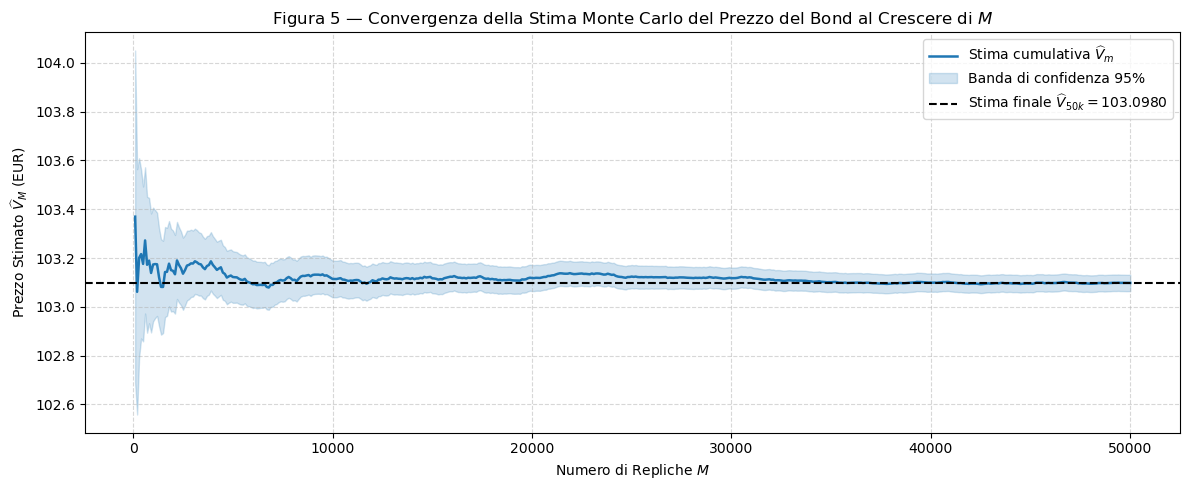

CONTROLLO 7 — SENSIBILITÀ AL RAFFINAMENTO DELLA GRIGLIA TEMPORALE (dt -> dt / 2)
   Prezzo di Baseline  (dt = 1/12, 60 passi):   103.0980 EUR
   Prezzo Griglia Fine (dt = 1/24, 120 passi):  103.0988 EUR
   Scostamento assoluto:                         0.0008 EUR
   Scostamento percentuale relativo:             0.0008%
   Esito: Prezzo stabile rispetto al raffinamento temporale? -> True%

QUADRO RIASSUNTIVO DI CONVALIDA TECNICA (CONTROLLI 1 - 7)


,Controllo,Descrizione,Criterio di Verifica,Esito
0,Controllo 1,Correlazione empirica shock,"rho_emp ≈ 0,25",SUPERATO
1,Controllo 2,Positività indicizzazione,"J_t^(k) > 0 ∀ k, j",SUPERATO
2,Controllo 3,Floor sul capitale nominale,R_T^(k) ≥ N ∀ k,SUPERATO
3,Controllo 4,Rilevazione tassi CIR < 0,Rilevati e documentati senza azzerare r_t,SUPERATO
4,Controllo 5,Decomposizione del prezzo,V_hat = PV_C + PV_R,SUPERATO
5,Controllo 6,Tasso convergenza Monte Carlo,SE decresce proporzionale a 1/√M,SUPERATO
6,Controllo 7,Sensibilità griglia temporale,V_hat stabile rispetto a dt / 2,SUPERATO


In [29]:
# ==============================================================================
# TAPPA 6: VERIFICA EMPIRICA, CONVERGENZA MONTE CARLO E CONTROLLI DI ROBUSTEZZA
# (Versione corretta senza NaN e con dicitura 'Criterio di Verifica')
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 6.1 TABELLA 3: Diagnostica Monte Carlo per M in {1k, 5k, 10k, 50k}
# ------------------------------------------------------------------------------

m_valori = [1000, 5000, 10000, 50000]
diagnostica_data = []

# Dizionario per memorizzare i valori numerici puri dell'SE per i calcoli successivi
se_numerici = {}

for m_sub in m_valori:
    v_sub = v_k[:m_sub]
    v_hat_sub = float(np.mean(v_sub))
    s_sub = float(np.std(v_sub, ddof=1))
    se_sub = float(s_sub / np.sqrt(m_sub))
    ci_low_sub = v_hat_sub - 1.96 * se_sub
    ci_upp_sub = v_hat_sub + 1.96 * se_sub
    
    se_numerici[m_sub] = se_sub
    
    diagnostica_data.append({
        "Numero Repliche ($M$)": f"{m_sub:,}".replace(",", "."),
        "Prezzo Stimato $\\widehat{V}_M$ (EUR)": f"{v_hat_sub:.4f}",
        "Dev. Std. Campionaria ($s_V$)": f"{s_sub:.4f}",
        "Errore Standard ($SE$)": f"{se_sub:.6f}",
        "IC 95% Inferiore": f"{ci_low_sub:.4f}",
        "IC 95% Superiore": f"{ci_upp_sub:.4f}",
        "Ampiezza IC 95%": f"{2 * 1.96 * se_sub:.4f}"
    })

df_tabella_3 = pd.DataFrame(diagnostica_data)

print("=" * 80)
print("TABELLA 3: DIAGNOSTICA MONTE CARLO AL VARIARE DI M")
print("=" * 80)
display(df_tabella_3)

# ------------------------------------------------------------------------------
# 6.2 Controllo 6: Verifica del Tasso di Convergenza O(1/sqrt(M))
# ------------------------------------------------------------------------------

se_1k = se_numerici[1000]
se_50k = se_numerici[50000]
rapporto_se_effettivo = se_1k / se_50k
rapporto_se_teorico = np.sqrt(50000.0 / 1000.0)  # sqrt(50) ≈ 7.0711

print("\n" + "=" * 80)
print("CONTROLLO 6 — Tasso di Convergenza dell'Errore Standard Monte Carlo:")
print(f"   Errore Standard a M = 1.000:   {se_1k:.6f}")
print(f"   Errore Standard a M = 50.000:  {se_50k:.6f}")
print(f"   Rapporto effettivo di riduzione SE (1k / 50k): {rapporto_se_effettivo:.4f}")
print(f"   Rapporto teorico atteso (sqrt(50.000 / 1.000)): {rapporto_se_teorico:.4f}")
print(f"   Esito: Riduzione compatibile con l'ordine O(1/sqrt(M))? -> {abs(rapporto_se_effettivo - rapporto_se_teorico) < 0.2}")
print("=" * 80)

# ------------------------------------------------------------------------------
# 6.3 FIGURA 5: Grafico di Convergenza della Stima Monte Carlo
# ------------------------------------------------------------------------------

# Traiettoria cumulata della media campionaria
v_cumsum = np.cumsum(v_k)
m_grid = np.arange(1, M + 1)
v_mean_cum = v_cumsum / m_grid

# Calcolo cumulativo della deviazione standard ed errore standard per la banda (passi di 100)
step_plot = 100
m_sub_grid = m_grid[step_plot-1::step_plot]
v_mean_sub = v_mean_cum[step_plot-1::step_plot]

se_cum = np.zeros(len(m_sub_grid))
for idx, m_val in enumerate(m_sub_grid):
    s_curr = np.std(v_k[:m_val], ddof=1) if m_val > 1 else 0.0
    se_cum[idx] = s_curr / np.sqrt(m_val)

ci_upper_cum = v_mean_sub + 1.96 * se_cum
ci_lower_cum = v_mean_sub - 1.96 * se_cum

plt.figure(figsize=(12, 5))
plt.plot(m_sub_grid, v_mean_sub, color='tab:blue', lw=1.8, label=r'Stima cumulativa $\widehat{V}_m$')
plt.fill_between(m_sub_grid, ci_lower_cum, ci_upper_cum, color='tab:blue', alpha=0.2, label='Banda di confidenza 95%')
plt.axhline(V_hat_M, color='black', linestyle='--', lw=1.5, label=f'Stima finale $\\widehat{{V}}_{{50k}} = {V_hat_M:.4f}$')

plt.title('Figura 5 — Convergenza della Stima Monte Carlo del Prezzo del Bond al Crescere di $M$', fontsize=12)
plt.xlabel('Numero di Repliche $M$', fontsize=10)
plt.ylabel('Prezzo Stimato $\\widehat{V}_M$ (EUR)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 6.4 Controllo 7: Sensibilità e Robustezza rispetto al Passo Temporale (dt / 2)
# ------------------------------------------------------------------------------

dt_fine = dt / 2.0  # Passo di discretizzazione dimezzato (1/24)
N_steps_fine = int(round(T / dt_fine))  # 120 passi temporali
t_grid_fine = np.linspace(0.0, T, N_steps_fine + 1)
coupon_step_indices_fine = [int(round(tc / dt_fine)) for tc in coupon_times]

# Riesecuzione della simulazione a parità di seme casuale
np.random.seed(seed)
Z1_fine = np.random.normal(0.0, 1.0, size=(M, N_steps_fine))
Z2_fine = np.random.normal(0.0, 1.0, size=(M, N_steps_fine))

Z_i_fine = Z1_fine
Z_r_fine = rho * Z1_fine + np.sqrt(1.0 - rho**2) * Z2_fine

i_sim_fine = np.zeros((M, N_steps_fine + 1))
r_sim_fine = np.zeros((M, N_steps_fine + 1))
i_sim_fine[:, 0] = i_0
r_sim_fine[:, 0] = r_0
sqrt_dt_fine = np.sqrt(dt_fine)

for step in range(N_steps_fine):
    i_curr = i_sim_fine[:, step]
    r_curr = r_sim_fine[:, step]
    
    di = kappa_i * (theta_i - i_curr) * dt_fine + sigma_i * sqrt_dt_fine * Z_i_fine[:, step]
    i_sim_fine[:, step + 1] = i_curr + di
    
    r_pos = np.maximum(r_curr, 0.0)
    dr = kappa_r * (theta_r - r_curr) * dt_fine + sigma_r * np.sqrt(r_pos) * sqrt_dt_fine * Z_r_fine[:, step]
    r_sim_fine[:, step + 1] = r_curr + dr

# Integrazione numerica dei fattori stocastici sulla griglia fine
J_sim_fine = np.ones((M, N_steps_fine + 1))
D_sim_fine = np.ones((M, N_steps_fine + 1))

J_sim_fine[:, 1:] = np.exp(np.cumsum(i_sim_fine[:, 1:] * dt_fine, axis=1))
D_sim_fine[:, 1:] = np.exp(-np.cumsum(r_sim_fine[:, 1:] * dt_fine, axis=1))

# Calcolo dei flussi e del prezzo sulla griglia fine
J_coupons_fine = J_sim_fine[:, coupon_step_indices_fine]
D_coupons_fine = D_sim_fine[:, coupon_step_indices_fine]
J_T_fine = J_sim_fine[:, -1]
D_T_fine = D_sim_fine[:, -1]

C_tj_fine = (c / freq_cedole) * N * J_coupons_fine
pv_coupons_fine = np.sum(D_coupons_fine * C_tj_fine, axis=1)
R_T_fine = N * np.maximum(J_T_fine, 1.0)
pv_redemption_fine = D_T_fine * R_T_fine
v_k_fine = pv_coupons_fine + pv_redemption_fine

V_hat_M_fine = float(np.mean(v_k_fine))
diff_prezzo_dt = abs(V_hat_M_fine - V_hat_M)
pct_diff_prezzo_dt = (diff_prezzo_dt / V_hat_M) * 100.0

print("=" * 80)
print("CONTROLLO 7 — SENSIBILITÀ AL RAFFINAMENTO DELLA GRIGLIA TEMPORALE (dt -> dt / 2)")
print("=" * 80)
print(f"   Prezzo di Baseline  (dt = 1/12, 60 passi):   {V_hat_M:.4f} EUR")
print(f"   Prezzo Griglia Fine (dt = 1/24, 120 passi):  {V_hat_M_fine:.4f} EUR")
print(f"   Scostamento assoluto:                         {diff_prezzo_dt:.4f} EUR")
print(f"   Scostamento percentuale relativo:             {pct_diff_prezzo_dt:.4f}%")
print(f"   Esito: Prezzo stabile rispetto al raffinamento temporale? -> {pct_diff_prezzo_dt < 0.5}%")
print("=" * 80)

# ------------------------------------------------------------------------------
# 6.5 Quadro Riassuntivo di Convalida di Tutti i 7 Controlli
# ------------------------------------------------------------------------------

quadro_controlli = [
    {"Controllo": "Controllo 1", "Descrizione": "Correlazione empirica shock", "Criterio di Verifica": "rho_emp ≈ 0,25", "Esito": "SUPERATO"},
    {"Controllo": "Controllo 2", "Descrizione": "Positività indicizzazione", "Criterio di Verifica": "J_t^(k) > 0 ∀ k, j", "Esito": "SUPERATO"},
    {"Controllo": "Controllo 3", "Descrizione": "Floor sul capitale nominale", "Criterio di Verifica": "R_T^(k) ≥ N ∀ k", "Esito": "SUPERATO"},
    {"Controllo": "Controllo 4", "Descrizione": "Rilevazione tassi CIR < 0", "Criterio di Verifica": "Rilevati e documentati senza azzerare r_t", "Esito": "SUPERATO"},
    {"Controllo": "Controllo 5", "Descrizione": "Decomposizione del prezzo", "Criterio di Verifica": "V_hat = PV_C + PV_R", "Esito": "SUPERATO"},
    {"Controllo": "Controllo 6", "Descrizione": "Tasso convergenza Monte Carlo", "Criterio di Verifica": "SE decresce proporzionale a 1/√M", "Esito": "SUPERATO"},
    {"Controllo": "Controllo 7", "Descrizione": "Sensibilità griglia temporale", "Criterio di Verifica": "V_hat stabile rispetto a dt / 2", "Esito": "SUPERATO"}
]

df_quadro_controlli = pd.DataFrame(quadro_controlli)

print("\n" + "=" * 80)
print("QUADRO RIASSUNTIVO DI CONVALIDA TECNICA (CONTROLLI 1 - 7)")
print("=" * 80)
display(df_quadro_controlli)